# Labware twin (replayable)
Bench labware from photos → parametric SBS remixes, Opentrons defs, Merkle custody. Swap the remix parameters in the first code cell and rebuild; the lab root changes only if something you can print changed.

In [1]:
import copy, os, sys
from pathlib import Path
if Path.cwd().name == 'notebooks': os.chdir('..')
sys.path.insert(0, os.getcwd())
from baebugs import labware_twin as lt

PRINTS = copy.deepcopy(lt.PRINTS)
# swap data here, e.g. measured tube OD + clearance for the 2 mL cryotube rack:
# PRINTS[1]['params']['hole_d'] = 13.0
{p['id']: {k: p['params'][k] for k in ('rows', 'cols', 'pitch', 'hole_d') if k in p['params']} for p in PRINTS}

{'print-rack-96': {'rows': 8, 'cols': 12, 'pitch': 9.0, 'hole_d': 5.8},
 'print-cryo-24': {'rows': 4, 'cols': 6, 'pitch': 19.3, 'hole_d': 13.2},
 'print-conical-15': {'rows': 3, 'cols': 5, 'pitch': 25.0, 'hole_d': 17.5},
 'print-conical-50': {'rows': 2, 'cols': 3, 'pitch': 35.0, 'hole_d': 29.5},
 'print-cryo-100': {'rows': 10, 'cols': 10, 'pitch': 13.0, 'hole_d': 12.6},
 'print-frame-sbs': {},
 'print-grid-mesh': {'rows': 2, 'cols': 3},
 'print-honeycomb': {}}

In [2]:
committed = lt.verify()   # re-hash every fragment, proof, STL/SCAD/JSON file and the custody chain
{k: committed[k] for k in ('ok', 'fragments', 'lab_root', 'fails')}

{'ok': True,
 'fragments': 230,
 'lab_root': 'd469e0e9b7f9395156a240f03ea1a4cf4249210ac2d4d7d0e6b91a458ea3aa6d',
 'fails': []}

In [3]:
import shutil
shutil.copytree(lt.OUT, 'runs/labware_twin', dirs_exist_ok=True)   # work on a copy; only changed parts re-render
info = lt.build('runs/labware_twin', PRINTS)
replay = lt.verify('runs/labware_twin')
{'lab_root': info['lab_root'], 'same_as_committed': info['lab_root'] == committed['lab_root'],
 'verified': replay['ok'], 'photo_breaks': info['breaks'], 'filament_usd_total': info['filament_usd_total']}

{'lab_root': 'd469e0e9b7f9395156a240f03ea1a4cf4249210ac2d4d7d0e6b91a458ea3aa6d',
 'same_as_committed': True,
 'verified': True,
 'photo_breaks': 16,
 'filament_usd_total': 8.36}

In [4]:
import pandas as pd
rows = [{'part': p['name'], 'footprint': f"{p['params']['footprint_x']} x {p['params']['footprint_y']}", **info['print_meta'][p['id']]} for p in PRINTS]
pd.DataFrame(rows)[['part', 'footprint', 'grams', 'usd', 'watertight']]

,part,footprint,grams,usd,watertight
0,"SBS 96 rack, 9 mm pitch",127.76 x 85.48,50.6,1.11,True
1,"SBS 4x6 rack, 2 mL cryotubes",127.76 x 85.48,56.0,1.23,True
2,"SBS 3x5 rack, 15 mL conicals",127.76 x 85.48,62.8,1.38,True
3,"SBS 2x3 rack, 50 mL conicals",127.76 x 85.48,61.2,1.35,True
4,"10x10 cryo grid insert, 133 mm",133.0 x 133.0,42.9,1.93,True
5,SBS lipped frame ('folder'),127.76 x 85.48,24.6,0.54,True
6,SBS 2x3 screened grid frame,127.76 x 85.48,24.3,0.54,True
7,Honeycomb insert for SBS frame,117.16 x 74.88,13.9,0.28,True


In [5]:
import json
parts = json.load(open('runs/labware_twin/merkle/parts.json'))
f = next(x for x in parts['print-cryo-24']['fragments'] if x['name'] == 'derivation')
# a remix commits to the roots of the observed parts it came from; walk its proof to the part root
lt.climb(f['leaf'], f['proof']) == parts['print-cryo-24']['root'], f['payload']

(True,
 {'from': {'obs-cryotube-2ml': '9ef010c792627133d4f35a9a7e9d0fd0a63a104ca30793361a22a931bfd6c4ad',
   'obs-microtube-50-purple': '594b053105fa6c1a2b5696ebccdeffa88d437267d9aca100836e2bb267142bc7'}})

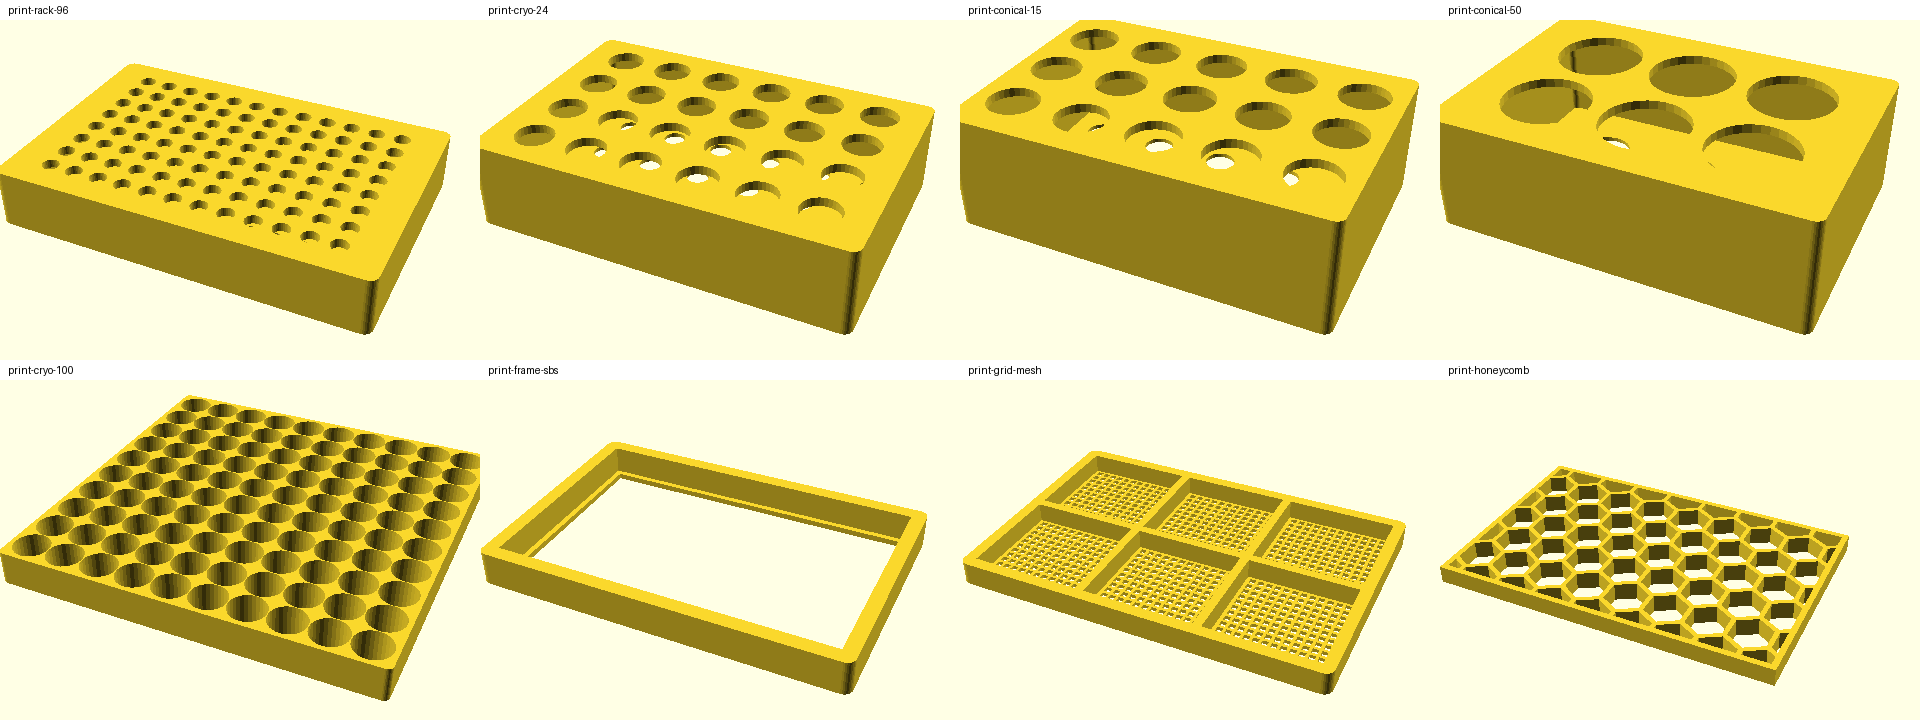

In [6]:
from IPython.display import Image
Image('print/labware/previews.png')